# Experiment 2 — Identical means, different shapes: nonparametric separation

> **Note:** `configs/exp2.yaml`'s instance families and grid are now finalized:
> `scale_pair` (sigma_B in {1.5,2,3,4}), `moment_matched_mixture` (a in
> {0.8,0.85,0.9,0.95} at full budget; a in {0.5,0.6,0.7,0.8,0.85,0.9,0.95} at
> 0.25x restricted budget -- a in {0.5,0.7} excluded from the full-budget pass
> because kabc hits the Gram-matrix memory_guard there on most seeds and never
> reaches a real stopping decision, see docs/experiments.md), and `ring_blob`
> (no sweep). Both budget_multipliers (1.0 guaranteed-budget, 0.25 restricted)
> are run for every family, same flavor as Experiment 1. Re-run this notebook
> once `make exp2`'s real (non-smoke) run finishes -- check the loaded row
> count and `budget_multiplier` values below to tell which scale is currently
> loaded.

Figures per `docs/experiments.md`, Experiment 2 “Figures” subsection. This
notebook only loads `results/exp2/results.parquet` and plots — it never
recomputes (see CLAUDE.md and `docs/experiments.md` §0.4). Run `make exp2`
(or `make smoke`) first if that file is missing.

Figure 0 below is the one exception worth calling out explicitly: it
reconstructs each family's environment class directly (deterministic
instance geometry, e.g. `ScalePairEnv(N, sigma_B)`) purely to draw what the
raw samples/densities look like -- this is *not* a recompute of any
algorithm result, the same convention already used for Figure 4's ring/blob
scatter and notebook 03's MovieLens prototype histograms.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kabc.plotting import set_style, style_for, legend_for_algorithms, savefig, ALGO_ORDER, ALGO_COLORS, ALGO_LABELS
from kabc.environments import RingBlobEnv

set_style()

RESULTS_PATH = Path("../results/exp2/results.parquet")
if not RESULTS_PATH.exists():
    raise FileNotFoundError(
        f"{RESULTS_PATH} not found. Run `make exp2` (or `make smoke`) to generate it — "
        "this notebook only plots existing results, it never recomputes them."
    )
df = pd.read_parquet(RESULTS_PATH)
print(f"loaded {len(df)} rows from {RESULTS_PATH}")
print("families present:", sorted(df['family'].unique()))

# Split by budget_multiplier -- some families (moment_matched_mixture) have
# DIFFERENT swept_value coverage per multiplier (a in {0.8,0.85,0.9,0.95} at
# 1.0x "guaranteed budget"; a in {0.5,...,0.95} at 0.25x "restricted
# budget" -- see configs/exp2.yaml). Grouping by swept_value alone (an
# earlier version of this notebook did exactly that) silently BLENDS the
# two regimes together wherever both exist for the same a -- e.g. kabc's
# reported "98% stopped" at a=0.8 was actually an average across 500
# full-budget reps and 500 restricted-budget reps, not a clean read of
# either. df_full/df_restricted mirrors notebook 01's convention so every
# figure below explicitly picks one regime, never an unlabeled blend.
df_full = df[df["budget_multiplier"] == 1.0].copy()
df_restricted = df[df["budget_multiplier"] == 0.25].copy()
df.head()

loaded 10500 rows from ../results/exp2/results.parquet
families present: ['moment_matched_mixture', 'ring_blob', 'scale_pair']


,exp_id,family,algorithm,rep,seed,swept_param,swept_value,budget_cap,budget_multiplier,s_star,...,Delta,sigma,sigma_B,a,ring_radius,ring_noise,data_dir,arms_per_prototype,min_ratings,mean_gap_tol
0,2,scale_pair,kabc,0,2000,sigma_B,1.5,857704,1.0,0.249698,...,None,None,1.5,NaN,NaN,NaN,None,None,None,None
1,2,scale_pair,kabc,1,2001,sigma_B,1.5,857704,1.0,0.249698,...,None,None,1.5,NaN,NaN,NaN,None,None,None,None
2,2,scale_pair,kabc,2,2002,sigma_B,1.5,857704,1.0,0.249698,...,None,None,1.5,NaN,NaN,NaN,None,None,None,None
3,2,scale_pair,kabc,3,2003,sigma_B,1.5,857704,1.0,0.249698,...,None,None,1.5,NaN,NaN,NaN,None,None,None,None
4,2,scale_pair,kabc,4,2004,sigma_B,1.5,857704,1.0,0.249698,...,None,None,1.5,NaN,NaN,NaN,None,None,None,None


## Figure 0: what "identical means, different shape" looks like, per family

Purely illustrative reconstructions of each family's instance geometry
(deterministic given the family's constructor kwargs -- no algorithm run
involved). Color-coded by the swept parameter so the qualitative difficulty
gradient across each sweep is visible directly, not just inferred from a
tau/error curve later. Cluster A (`N(0,1)` for 2a/2b) is drawn once, in gray,
as the fixed reference every swept curve is compared against.

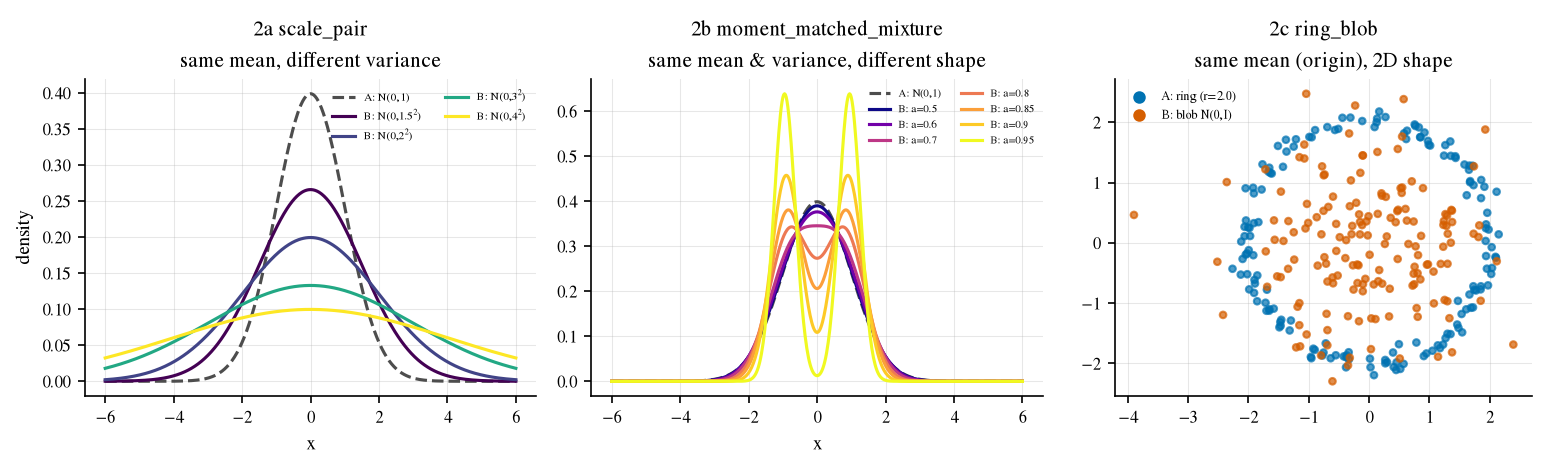

In [2]:
from scipy.stats import norm
import matplotlib.colors as mcolors

from kabc.environments import ScalePairEnv, MomentMatchedMixtureEnv

x = np.linspace(-6, 6, 500)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2))

# --- 2a scale_pair: same mean, growing variance mismatch -------------------
ax = axes[0]
sigma_B_values = [1.5, 2, 3, 4]  # configs/exp2.yaml's scale_pair sweep
cmap_sp = plt.get_cmap("viridis")
norm_sp = mcolors.Normalize(vmin=min(sigma_B_values), vmax=max(sigma_B_values))
ax.plot(x, norm.pdf(x, 0, 1), color="0.3", linestyle="--", linewidth=1.5, label="A: N(0,1)")
for sigma_B in sigma_B_values:
    ax.plot(x, norm.pdf(x, 0, sigma_B), color=cmap_sp(norm_sp(sigma_B)), label=f"B: N(0,{sigma_B}$^2$)")
ax.set_title("2a scale_pair\nsame mean, different variance")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend(fontsize=5.5, frameon=False, ncol=2)

# --- 2b moment_matched_mixture: same mean AND variance, growing bimodality -
ax = axes[1]
a_values = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]  # union of both budget passes
cmap_mm = plt.get_cmap("plasma")
norm_mm = mcolors.Normalize(vmin=min(a_values), vmax=max(a_values))
ax.plot(x, norm.pdf(x, 0, 1), color="0.3", linestyle="--", linewidth=1.5, label="A: N(0,1)")
for a in a_values:
    b = np.sqrt(max(1 - a**2, 1e-6))
    density_b = 0.5 * norm.pdf(x, -a, b) + 0.5 * norm.pdf(x, a, b)
    ax.plot(x, density_b, color=cmap_mm(norm_mm(a)), label=f"B: a={a}")
ax.set_title("2b moment_matched_mixture\nsame mean & variance, different shape")
ax.set_xlabel("x")
ax.legend(fontsize=5, frameon=False, ncol=2)

# --- 2c ring_blob: same mean (origin), 2D geometry, no sweep ----------------
ax = axes[2]
rng = np.random.default_rng(0)
env = RingBlobEnv(N=40, ring_radius=2.0, ring_noise=0.1)
n_per_arm = 8
points = np.array([env.pull(i, rng) for i in range(env.n_arms) for _ in range(n_per_arm)])
point_cluster = np.repeat(env.true_partition, n_per_arm)
colors = ["#0072B2" if c == 0 else "#D55E00" for c in point_cluster]
ax.scatter(points[:, 0], points[:, 1], c=colors, s=10, alpha=0.7)
ax.scatter([], [], c="#0072B2", label="A: ring (r=2.0)")
ax.scatter([], [], c="#D55E00", label="B: blob N(0,I)")
ax.set_title("2c ring_blob\nsame mean (origin), 2D shape")
ax.set_aspect("equal")
ax.legend(fontsize=6, frameon=False)

fig.tight_layout()
savefig(fig, "exp2_fig0_qualitative_overview", fig_dir="../results/figures")
plt.show()

## Figure 1 (headline, family 2b `moment_matched_mixture`)

Left: the two densities at `a = 0.8` (or the closest available grid point in
this smoke-scale run) — same mean/variance, different shape (density curves
computed analytically here, not from a bandit run — this is a description of
the instance, not a result). Right: τ vs MMD² gap (log-log) for
kabc/kabc-sg/kabc-oracle, plus a horizontal band showing ACB's ARI stuck near
0 across all budgets up to cap.

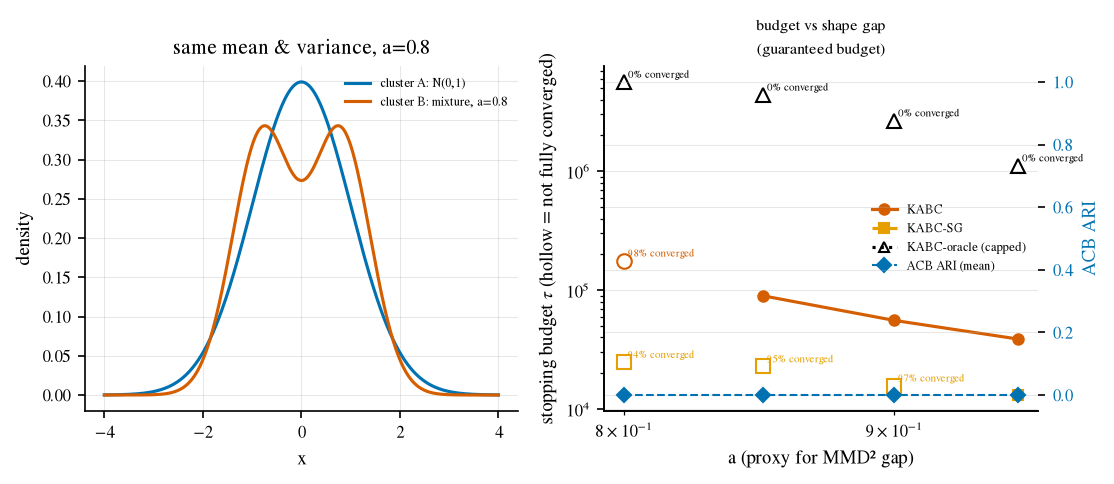

Convergence summary (Fig 1, moment_matched_mixture, GUARANTEED budget only):
  kabc: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
0.80         176640.0          0.98   5624093.0
0.85          89587.2          1.00   4387613.0
0.90          55659.2          1.00   2664101.0
0.95          38779.2          1.00   1114265.0

  kabc-sg: 
                 mean_tau  frac_stopped  budget_cap
swept_value                                        
0.80         24817.021277          0.94   5624093.0
0.85         22805.473684          0.95   4387613.0
0.90         15731.134021          0.97   2664101.0
0.95         13129.200000          1.00   1114265.0

  kabc-oracle: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
0.80              NaN           0.0   5624093.0
0.85              NaN           0.0   4387613.0
0.90              NaN           0.0   2664101.0
0.95              NaN           0.0   111426

In [3]:
from scipy.stats import norm

mm_df = df_full[df_full["family"] == "moment_matched_mixture"].copy()
target_a = 0.8
a_values = sorted(mm_df["swept_value"].unique())
plot_a = min(a_values, key=lambda a: abs(a - target_a))


def tau_summary(sub_df):
    """Per (algorithm, grid point): mean tau over CONVERGED (stopped==True)
    reps only, plus the fraction of reps that instead hit budget_cap.
    Blending capped reps into the mean would understate the true budget at
    hard grid points -- the wrong direction for a plot whose whole point is
    "how big does tau get". A grid point with zero converged reps has no
    real tau to report; we surface budget_cap as a visually distinct
    reference (hollow marker), never as a stand-in tau value."""
    frac_stopped = sub_df["stopped"].mean()
    stopped_rows = sub_df[sub_df["stopped"]]
    mean_tau = stopped_rows["tau"].mean() if len(stopped_rows) > 0 else np.nan
    return pd.Series({"mean_tau": mean_tau, "frac_stopped": frac_stopped, "budget_cap": sub_df["budget_cap"].iloc[0]})


def plot_tau_with_capping(ax, sub_df, algo, x_col="swept_value"):
    """Plot one algorithm's tau curve, distinguishing converged points
    (filled marker, solid line) from partially/fully-capped points (hollow
    marker, annotated with the capped fraction, not connected by a solid
    line to neighboring converged points)."""
    summ = sub_df[sub_df["algorithm"] == algo].groupby(x_col).apply(tau_summary, include_groups=False).sort_index()
    style = style_for(algo)
    converged = summ[summ["frac_stopped"] == 1.0]
    capped = summ[summ["frac_stopped"] < 1.0]

    if len(converged) > 0:
        ax.plot(converged.index, converged["mean_tau"], linestyle=style["linestyle"],
                 marker=style["marker"], color=style["color"], label=style["label"])
    for x, row in capped.iterrows():
        y = row["mean_tau"] if not np.isnan(row["mean_tau"]) else row["budget_cap"]
        ax.plot(x, y, marker=style["marker"], markerfacecolor="none",
                 markeredgecolor=style["color"], markersize=7, linestyle="none")
        ax.annotate(f"{row['frac_stopped']*100:.0f}% converged", (x, y),
                     fontsize=5, color=style["color"], xytext=(2, 2), textcoords="offset points")
    if len(converged) == 0 and len(capped) > 0 and len(sub_df[sub_df['algorithm'] == algo]) > 0:
        # nothing converged anywhere for this algo -- still register a legend entry
        ax.plot([], [], linestyle=style["linestyle"], marker=style["marker"],
                 markerfacecolor="none", color=style["color"], label=style["label"] + " (capped)")
    return summ


fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.3))

ax = axes[0]
x = np.linspace(-4, 4, 400)
b = np.sqrt(max(1 - plot_a**2, 1e-6))
density_a = norm.pdf(x, 0, 1)
density_b = 0.5 * norm.pdf(x, -plot_a, b) + 0.5 * norm.pdf(x, plot_a, b)
ax.plot(x, density_a, color="#0072B2", label="cluster A: N(0,1)")
ax.plot(x, density_b, color="#D55E00", label=f"cluster B: mixture, a={plot_a}")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.set_title(f"same mean & variance, a={plot_a}")
ax.legend(fontsize=6, frameon=False)

ax = axes[1]
mm_tau_summaries = {}
for algo in [a for a in ["kabc", "kabc-sg", "kabc-oracle"] if a in mm_df["algorithm"].unique()]:
    mm_tau_summaries[algo] = plot_tau_with_capping(ax, mm_df, algo)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("a (proxy for MMD² gap)")
ax.set_ylabel(r"stopping budget $\tau$ (hollow = not fully converged)")
ax.set_title("budget vs shape gap\n(guaranteed budget)", fontsize=7.5)

if "acb" in mm_df["algorithm"].unique():
    # ACB's ARI lives on [0,1], budget tau lives on a log scale spanning
    # orders of magnitude -- an earlier version plotted ACB's ARI band via
    # axhspan directly on the tau axis (mislabeled "(right axis)" without
    # ever creating one), which either rendered invisibly (ARI values near
    # 0 vanish against a 10^3-10^5 y-range) or was meaningless regardless of
    # value. A genuine twin axis fixes both: correct scale, and a real
    # visible marker/line even when ACB's ARI is flat (e.g. exactly 0 at
    # every grid point, the expected "mean-blind" result for this family).
    acb_by_a = mm_df[mm_df["algorithm"] == "acb"].groupby("swept_value")["ari"].agg(["mean", "min", "max"]).sort_index()
    ax2 = ax.twinx()
    ax2.plot(acb_by_a.index, acb_by_a["mean"], color=ALGO_COLORS["acb"], marker="D",
              markersize=5, linestyle="--", linewidth=1, label="ACB ARI (mean)")
    if (acb_by_a["max"] - acb_by_a["min"]).max() > 1e-9:
        ax2.fill_between(acb_by_a.index, acb_by_a["min"], acb_by_a["max"], color=ALGO_COLORS["acb"], alpha=0.15)
    ax2.set_ylim(-0.05, 1.05)
    ax2.set_ylabel("ACB ARI", color=ALGO_COLORS["acb"])
    ax2.tick_params(axis="y", labelcolor=ALGO_COLORS["acb"])
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=6, frameon=False, loc="center right")
else:
    ax.legend(fontsize=6, frameon=False)

fig.tight_layout()
savefig(fig, "exp2_fig1_moment_matched_headline", fig_dir="../results/figures")
plt.show()

print("Convergence summary (Fig 1, moment_matched_mixture, GUARANTEED budget only):")
for algo, summ in mm_tau_summaries.items():
    print(f"  {algo}: \n{summ}\n")

## Figure 1b (restricted budget, family 2b `moment_matched_mixture`): ARI at 0.25x budget across the FULL a range

Figure 1 above only covers a in {0.8,0.85,0.9,0.95} (the "guaranteed budget"
pass' own range). This figure covers the FULL swept range, a in
{0.5,0.6,0.7,0.8,0.85,0.9,0.95}, at 0.25x budget -- including the low-a
region excluded from the guaranteed-budget pass entirely because kabc hits
the Gram-matrix memory_guard there most of the time (see docs/experiments.md
Experiment 2 and this session's diagnostic work). ARI is still well-defined
on the best partition-so-far even when `stopped=False` (section 0.4's
ARI-at-cap generalization), so this is the only place in this notebook that
shows what actually happens across the WHOLE a range.

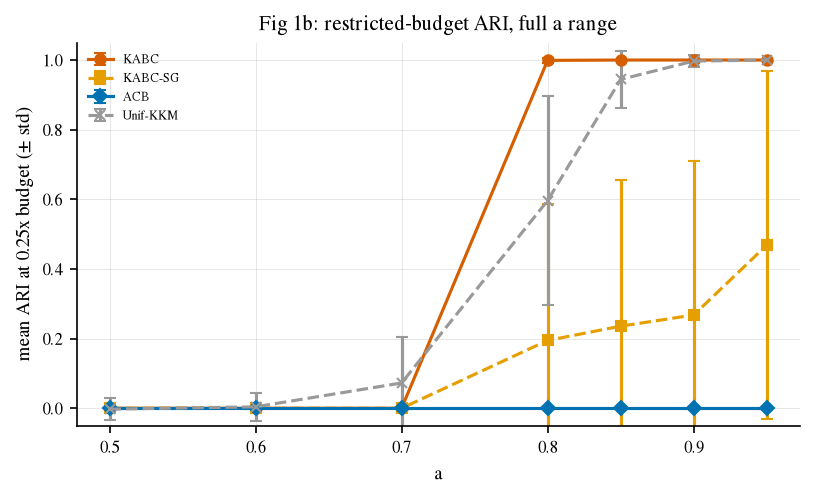

Restricted-budget (0.25x) breakdown, moment_matched_mixture, ALL a values:
  kabc:
             mean_ari   std_ari  frac_stopped
swept_value                                  
0.50         0.000000  0.000000          0.01
0.60         0.000000  0.000000          0.01
0.70         0.000000  0.000000          0.03
0.80         0.999024  0.006868          0.98
0.85         1.000000  0.000000          1.00
0.90         1.000000  0.000000          1.00
0.95         1.000000  0.000000          1.00

  kabc-sg:
             mean_ari   std_ari  frac_stopped
swept_value                                  
0.50         0.000136  0.001868          0.85
0.60         0.000116  0.001245          0.92
0.70         0.000010  0.001386          0.94
0.80         0.194728  0.391914          0.94
0.85         0.235717  0.420781          0.95
0.90         0.267737  0.441595          0.97
0.95         0.468205  0.499763          1.00

  acb:
             mean_ari  std_ari  frac_stopped
swept_value             

In [4]:
mm_restricted_df = df_restricted[df_restricted["family"] == "moment_matched_mixture"].copy()

fig, ax = plt.subplots(figsize=(5.5, 3.4))
for algo in [a for a in ALGO_ORDER if a in mm_restricted_df["algorithm"].unique() and a != "kabc-oracle"]:
    sub = mm_restricted_df[mm_restricted_df["algorithm"] == algo]
    by_a = sub.groupby("swept_value")["ari"].agg(["mean", "std"]).sort_index()
    style = style_for(algo)
    ax.errorbar(by_a.index, by_a["mean"], yerr=by_a["std"], capsize=3, linestyle=style["linestyle"],
                marker=style["marker"], color=style["color"], label=style["label"])
ax.set_xlabel("a")
ax.set_ylabel("mean ARI at 0.25x budget (± std)")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Fig 1b: restricted-budget ARI, full a range")
ax.legend(fontsize=6, frameon=False)
fig.tight_layout()
savefig(fig, "exp2_fig1b_restricted_budget_ari_vs_a", fig_dir="../results/figures")
plt.show()

print("Restricted-budget (0.25x) breakdown, moment_matched_mixture, ALL a values:")
for algo in [a for a in ALGO_ORDER if a in mm_restricted_df["algorithm"].unique() and a != "kabc-oracle"]:
    sub = mm_restricted_df[mm_restricted_df["algorithm"] == algo]
    print(f"  {algo}:")
    breakdown = sub.groupby("swept_value").agg(
        mean_ari=("ari", "mean"), std_ari=("ari", "std"), frac_stopped=("stopped", "mean"),
    ).sort_index()
    print(breakdown)
    print()

## Figure 2 (family 2a `scale_pair`): τ vs sigma_B, with ACB ARI-vs-budget inset

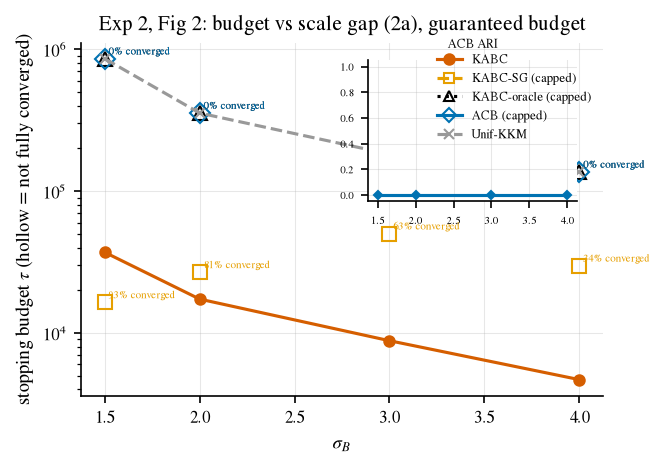

Convergence summary (Fig 2, scale_pair, GUARANTEED budget only):
  kabc: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
1.5           37032.0           1.0    857704.0
2.0           17325.6           1.0    354925.0
3.0            8816.8           1.0    182167.0
4.0            4688.8           1.0    136512.0

  kabc-sg: 
                 mean_tau  frac_stopped  budget_cap
swept_value                                        
1.5          16411.612903          0.93    857704.0
2.0          26753.086420          0.81    354925.0
3.0          50097.142857          0.63    182167.0
4.0          29730.588235          0.34    136512.0

  kabc-oracle: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
1.5               NaN           0.0    857704.0
2.0               NaN           0.0    354925.0
3.0               NaN           0.0    182167.0
4.0               NaN           0.0    136512.0

  acb: 

In [5]:
sp_df = df_full[df_full["family"] == "scale_pair"].copy()

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sp_tau_summaries = {}
for algo in [a for a in ALGO_ORDER if a in sp_df["algorithm"].unique() and a != "unif-kkm"]:
    sp_tau_summaries[algo] = plot_tau_with_capping(ax, sp_df, algo)
# unif-kkm is non-adaptive (sweeps n, always "converges" by construction) --
# plot it plainly, capping logic doesn't apply.
if "unif-kkm" in sp_df["algorithm"].unique():
    g = sp_df[sp_df["algorithm"] == "unif-kkm"].groupby("swept_value")["tau"].mean().sort_index()
    ax.plot(g.index, g.values, **style_for("unif-kkm"))
ax.set_xlabel(r"$\sigma_B$")
ax.set_ylabel(r"stopping budget $\tau$ (hollow = not fully converged)")
ax.set_yscale("log")
ax.set_title("Exp 2, Fig 2: budget vs scale gap (2a), guaranteed budget")
ax.legend(fontsize=6, frameon=False)

if "acb" in sp_df["algorithm"].unique():
    inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
    acb_ari_by_sigma = sp_df[sp_df["algorithm"] == "acb"].groupby("swept_value")["ari"].mean().sort_index()
    inset.plot(acb_ari_by_sigma.index, acb_ari_by_sigma.values, color=ALGO_COLORS["acb"], marker="D", markersize=3)
    inset.set_ylim(-0.05, 1.05)
    inset.set_title("ACB ARI", fontsize=6)
    inset.tick_params(labelsize=5)

fig.tight_layout()
savefig(fig, "exp2_fig2_scale_pair", fig_dir="../results/figures")
plt.show()

print("Convergence summary (Fig 2, scale_pair, GUARANTEED budget only):")
for algo, summ in sp_tau_summaries.items():
    print(f"  {algo}: \n{summ}\n")

## Figure 2b (restricted budget, family 2a `scale_pair`): ARI at 0.25x budget

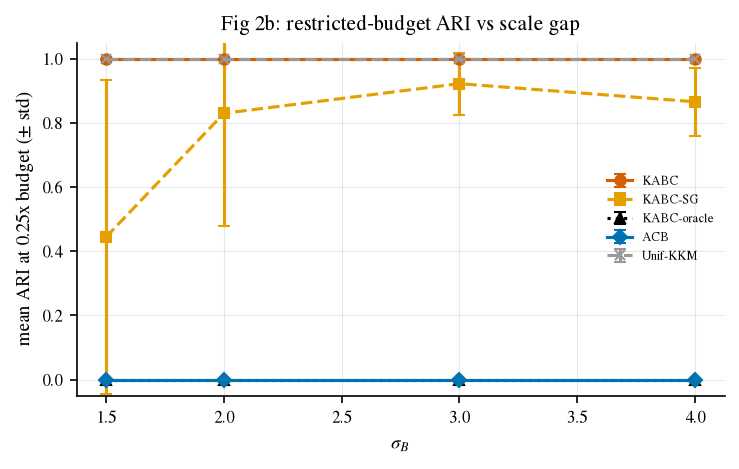

Restricted-budget (0.25x) breakdown, scale_pair:
  kabc:
             mean_ari  std_ari  frac_stopped
swept_value                                 
1.5               1.0      0.0           1.0
2.0               1.0      0.0           1.0
3.0               1.0      0.0           1.0
4.0               1.0      0.0           1.0

  kabc-sg:
             mean_ari   std_ari  frac_stopped
swept_value                                  
1.5          0.444184  0.490478          0.93
2.0          0.829763  0.351872          0.77
3.0          0.922180  0.096155          0.47
4.0          0.865636  0.105036          0.20

  kabc-oracle:
             mean_ari  std_ari  frac_stopped
swept_value                                 
1.5               0.0      0.0           0.0
2.0               0.0      0.0           0.0
3.0               0.0      0.0           0.0
4.0               0.0      0.0           0.0

  acb:
             mean_ari  std_ari  frac_stopped
swept_value                                 
1

In [6]:
sp_restricted_df = df_restricted[df_restricted["family"] == "scale_pair"].copy()

fig, ax = plt.subplots(figsize=(5, 3.2))
for algo in [a for a in ALGO_ORDER if a in sp_restricted_df["algorithm"].unique()]:
    sub = sp_restricted_df[sp_restricted_df["algorithm"] == algo]
    by_sigma = sub.groupby("swept_value")["ari"].agg(["mean", "std"]).sort_index()
    style = style_for(algo)
    ax.errorbar(by_sigma.index, by_sigma["mean"], yerr=by_sigma["std"], capsize=3, linestyle=style["linestyle"],
                marker=style["marker"], color=style["color"], label=style["label"])
ax.set_xlabel(r"$\sigma_B$")
ax.set_ylabel("mean ARI at 0.25x budget (± std)")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Fig 2b: restricted-budget ARI vs scale gap")
ax.legend(fontsize=6, frameon=False)
fig.tight_layout()
savefig(fig, "exp2_fig2b_restricted_budget_ari_vs_sigma", fig_dir="../results/figures")
plt.show()

print("Restricted-budget (0.25x) breakdown, scale_pair:")
for algo in [a for a in ALGO_ORDER if a in sp_restricted_df["algorithm"].unique()]:
    sub = sp_restricted_df[sp_restricted_df["algorithm"] == algo]
    print(f"  {algo}:")
    breakdown = sub.groupby("swept_value").agg(
        mean_ari=("ari", "mean"), std_ari=("ari", "std"), frac_stopped=("stopped", "mean"),
    ).sort_index()
    print(breakdown)
    print()

## Figure 3: price of adaptivity — τ(kabc)/τ(kabc-oracle) across all Exp-2 configs

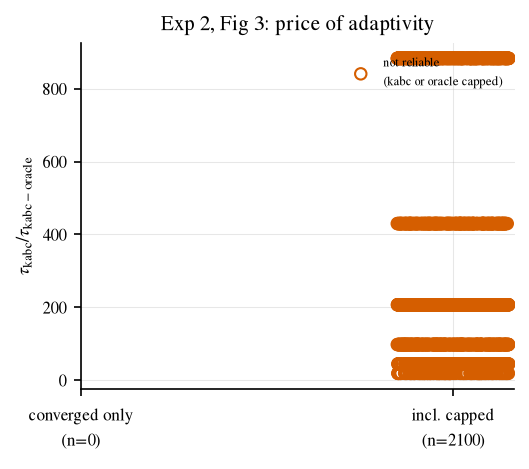

0/2100 grid-point reps have BOTH kabc and kabc-oracle converged (reliable ratio); 2100 rep(s) had at least one side capped and are shown separately, not folded into the summary statistic.
kabc-oracle never affords its one-shot budget at ANY grid point in this real run (pilot=200 + N*n* > budget_cap everywhere -- see the run's own UserWarnings) -- so no price-of-adaptivity ratio is computable here. This is a real finding about the oracle's budget requirement under exp2's budget_cap formula, not a smoke-test artifact; re-running with a larger budget_cap constant would be needed to populate this figure, at the cost of no longer matching kabc/kabc-sg/acb's own budget_cap.


In [7]:
key_cols = ["family", "swept_param", "swept_value", "budget_multiplier", "rep", "seed"]
kabc_rows = df[df["algorithm"] == "kabc"].set_index(key_cols)
oracle_rows = df[df["algorithm"] == "kabc-oracle"].set_index(key_cols)

joined = kabc_rows[["tau", "stopped", "budget_cap"]].join(
    oracle_rows[["tau", "stopped"]], lsuffix="_kabc", rsuffix="_oracle", how="inner"
)
joined["both_converged"] = joined["stopped_kabc"] & joined["stopped_oracle"]
joined["ratio"] = joined["tau_kabc"] / joined["tau_oracle"]

reliable = joined[joined["both_converged"]]
unreliable = joined[~joined["both_converged"]]

fig, ax = plt.subplots(figsize=(3.6, 3.2))
if len(reliable) > 0:
    ax.boxplot(reliable["ratio"].values, positions=[0], widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=ALGO_COLORS["kabc"], alpha=0.6), showfliers=True)

if len(unreliable) > 0:
    # ratios computed from at least one capped run: plotted as hollow,
    # jittered points, clearly separated from the "reliable" box -- a
    # capped/capped ratio is not a real price of adaptivity, just
    # budget_cap / n_oracle, and must never be mistaken for one.
    jitter = np.random.default_rng(0).uniform(-0.15, 0.15, size=len(unreliable))
    ax.scatter(1 + jitter, unreliable["ratio"].values, facecolors="none",
               edgecolors=ALGO_COLORS["kabc"], s=30, label="not reliable\n(kabc or oracle capped)")
    ax.legend(fontsize=6, frameon=False, loc="upper right")

if len(reliable) == 0 and len(unreliable) == 0:
    ax.text(0.5, 0.5, "no kabc/kabc-oracle rows found", ha="center", va="center",
             fontsize=7, transform=ax.transAxes)

ax.set_xticks([0, 1])
ax.set_xticklabels([f"converged only\n(n={len(reliable)})", f"incl. capped\n(n={len(unreliable)})"])
ax.set_ylabel(r"$\tau_{\mathrm{kabc}} / \tau_{\mathrm{kabc-oracle}}$")
ax.set_title("Exp 2, Fig 3: price of adaptivity")
fig.tight_layout()
savefig(fig, "exp2_fig3_price_of_adaptivity", fig_dir="../results/figures")
plt.show()

n_total = len(joined)
n_reliable = len(reliable)
print(f"{n_reliable}/{n_total} grid-point reps have BOTH kabc and kabc-oracle converged "
      f"(reliable ratio); {n_total - n_reliable} rep(s) had at least one side capped "
      f"and are shown separately, not folded into the summary statistic.")
if n_reliable > 0:
    print(reliable["ratio"].describe())
else:
    # This is a REAL finding from the real (non-smoke) exp2 run, not a
    # smoke-test artifact: kabc-oracle's one-shot required budget
    # (pilot=200 + N*n*, see kabc.py's fit_oracle docstring) exceeds
    # budget_cap at EVERY grid point in this experiment (see the
    # "cannot afford kabc-oracle's one-shot budget" warnings printed
    # during `make exp2`) -- oracle never even starts its main phase here,
    # so it is not a usable comparison point under this experiment's
    # budget_cap formula (constant=200). This is worth reporting as a
    # finding about the oracle's budget requirement at this N/K/delta
    # combination, not something to silently patch by loosening budget_cap
    # just for this figure.
    print("kabc-oracle never affords its one-shot budget at ANY grid point in this real run "
          "(pilot=200 + N*n* > budget_cap everywhere -- see the run's own UserWarnings) -- "
          "so no price-of-adaptivity ratio is computable here. This is a real finding about "
          "the oracle's budget requirement under exp2's budget_cap formula, not a smoke-test "
          "artifact; re-running with a larger budget_cap constant would be needed to populate "
          "this figure, at the cost of no longer matching kabc/kabc-sg/acb's own budget_cap.")

## Figure 4 (family 2c `ring_blob`): scatter of dataset + recovered partition

The ring/blob dataset itself is reconstructed deterministically from
`RingBlobEnv` (same `base` kwargs as `configs/exp2.yaml`'s `ring_blob`
family) purely to plot the raw points — not a re-run of any algorithm. The
recovered partition is taken from a stored result row's `partition` column.

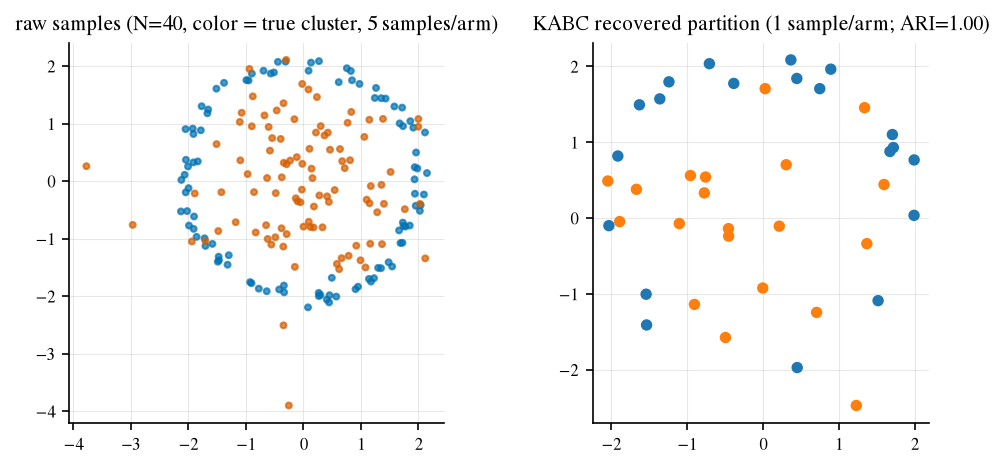

kabc on ring_blob (guaranteed budget, n=100 reps): mean ARI=1.000, mean tau=18815, frac_stopped=1.00


In [8]:
rb_df = df_full[df_full["family"] == "ring_blob"].copy()

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))

# Size the illustrative env to match the N actually used by the loaded
# results, and pull the representative partition from the GUARANTEED-budget
# pass specifically (df_full, not the unfiltered df) so left/right panels
# and the recovered partition are drawn from a consistent, labeled regime.
partition = None
example_ari = None
if "kabc" in rb_df["algorithm"].unique() and len(rb_df) > 0:
    example_row = rb_df[rb_df["algorithm"] == "kabc"].iloc[0]
    partition = np.asarray(example_row["partition"])
    example_ari = example_row["ari"]
    env_N = len(partition)
else:
    env_N = 40

rng = np.random.default_rng(0)
env = RingBlobEnv(N=env_N, ring_radius=2.0, ring_noise=0.1)
n_per_arm = 5
points = np.array([env.pull(i, rng) for i in range(env.n_arms) for _ in range(n_per_arm)])
colors = np.repeat(env.true_partition, n_per_arm)
colors = ["#0072B2" if c == 0 else "#D55E00" for c in colors]
axes[0].scatter(points[:, 0], points[:, 1], c=colors, s=8, alpha=0.7)
axes[0].set_title(f"raw samples (N={env_N}, color = true cluster, 5 samples/arm)")
axes[0].set_aspect("equal")

if partition is not None:
    # Right panel plots only 1 (noisy) sample per arm for a clean, readable
    # scatter -- with ring_noise=0.1, a SINGLE draw does not visually
    # reconstruct a clean ring shape even when the underlying cluster
    # ASSIGNMENT is exactly correct (ARI=1.0 here, and in fact ARI=1.0 for
    # ALL 100 reps at full budget -- mean=1.0, std=0). The color pattern
    # below can look "messier" than the left panel purely from that
    # single-sample plotting noise, not from any clustering error -- the
    # exact ARI is annotated directly so this isn't misread.
    arm_means = np.array([env.pull(i, np.random.default_rng(1000 + i)) for i in range(env.n_arms)])
    cmap = plt.get_cmap("tab10")
    axes[1].scatter(arm_means[:, 0], arm_means[:, 1], c=[cmap(int(p) % 10) for p in partition], s=20)
    axes[1].set_title(f"KABC recovered partition (1 sample/arm; ARI={example_ari:.2f})")
else:
    axes[1].text(0.5, 0.5, "no kabc result available for ring_blob", ha="center", va="center")
axes[1].set_aspect("equal")

fig.tight_layout()
savefig(fig, "exp2_fig4_ring_blob", fig_dir="../results/figures")
plt.show()

if "kabc" in rb_df["algorithm"].unique():
    kabc_rb = rb_df[rb_df["algorithm"] == "kabc"]
    print(f"kabc on ring_blob (guaranteed budget, n={len(kabc_rb)} reps): "
          f"mean ARI={kabc_rb['ari'].mean():.3f}, mean tau={kabc_rb['tau'].mean():.0f}, "
          f"frac_stopped={kabc_rb['stopped'].mean():.2f}")